## Heart Disease Prediction System

### Machine Learning-Based Healthcare Risk Classification

#### **Project Overview**

#### This project aims to develop a machine learning system that classifies the presence or absence of heart disease using patient health attributes. Multiple classification algorithms will be trained and evaluated to compare their predictive performance.

#### **Technology Stack:** Python · Pandas · NumPy · Matplotlib · Seaborn · Scikit-learn · XGBoost · Streamlit

#### **Dataset:** UCI Machine Learning Repository — Heart Disease Dataset

#### **Project Objectives**

#### * Perform data cleaning and exploratory data analysis (EDA).
#### * Identify relevant features associated with the target variable.
#### * Train and evaluate multiple machine learning classification models.
#### * Compare model performance using appropriate evaluation metrics.
#### * Develop an interactive web application using Streamlit.

#### > **Disclaimer:** This project is intended for educational and research purposes only. Its predictions are not a substitute for professional medical diagnosis.


## 1. Import Required Libraries

#### The following libraries will support data manipulation, numerical computation, visualization, and machine learning model development.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Lets load data set

In [3]:
columns = ['age', 'sex', 'cp', 'trestbps', 'chol','fbs', 'restecg', 'thalach', 'exang','oldpeak', 'slope', 'ca', 'thal', 'target']
df = pd.read_csv('processed.cleveland.data',header=None,names=columns,na_values='?')

In [4]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Data Inspection

#### Before preprocessing, we will examine the dataset's structure, data types, and missing values.

In [5]:
print("Dataset Dimensions:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df['target'].value_counts().sort_index())

Dataset Dimensions: (303, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope     

## now Data Cleaning and Preprocessing

In [6]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [7]:
print("Missing Values Before Cleaning:\n")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values Before Cleaning:

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Total Missing Values: 6


In [8]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (303, 14)


In [10]:
df['ca'] = df['ca'].fillna(df['ca'].median())
df['thal'] = df['thal'].fillna(df['thal'].median())

print("Missing Values After Cleaning:\n")
print(df.isnull().sum())

Missing Values After Cleaning:

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [11]:
df['target'] = (df['target'] > 0).astype(int)

print(df['target'].value_counts())

target
0    164
1    139
Name: count, dtype: int64


## Preprocessing Summary

#### The dataset has been prepared for binary classification.

#### The preprocessing steps include duplicate removal, missing-value imputation, and target transformation.

### Target Classes

#### 0: No heart disease detected in the dataset.
#### 1: Heart disease present in the dataset.

## EDA

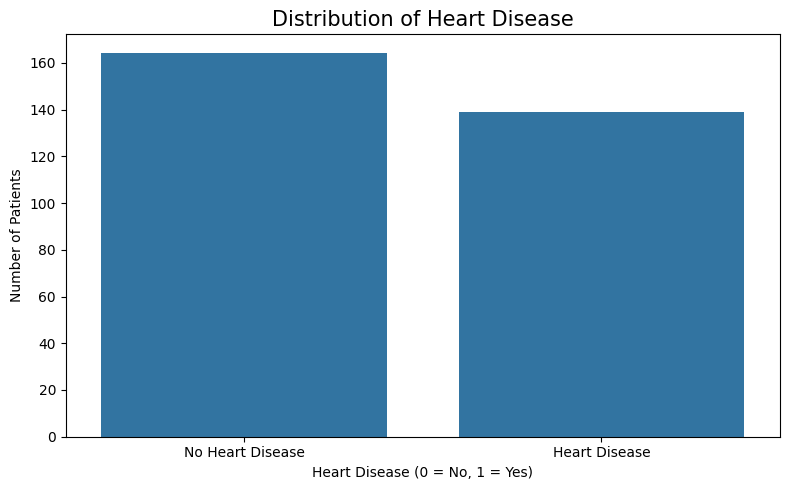

In [13]:
## 1. Distribution of Heart Disease
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='target')

plt.title('Distribution of Heart Disease', fontsize=15)
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.xticks([0, 1], ['No Heart Disease', 'Heart Disease'])

plt.tight_layout()
plt.show()

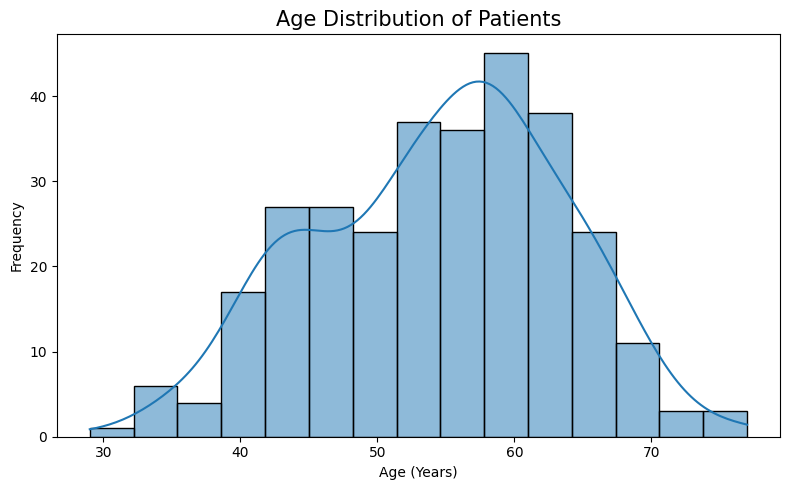

In [14]:
## 2 Age Distribution of Patients
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=15, kde=True)

plt.title('Age Distribution of Patients', fontsize=15)
plt.xlabel('Age (Years)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

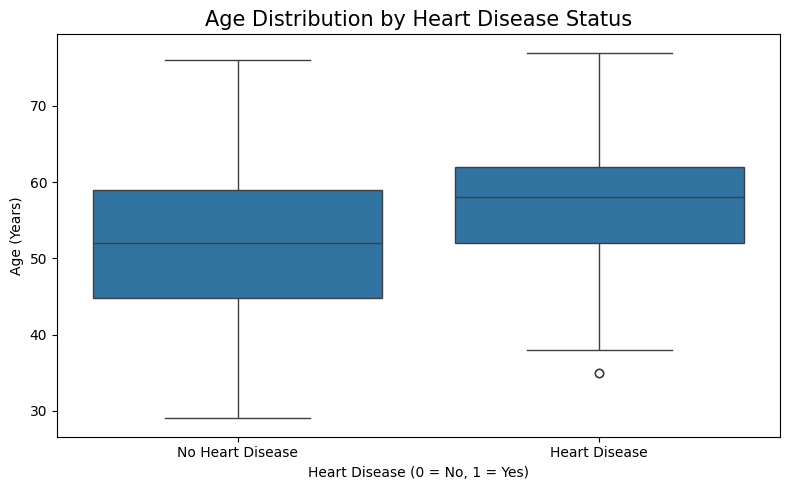

In [15]:
## 3 Relationship Between Age and Heart Disease
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='target', y='age')

plt.title('Age Distribution by Heart Disease Status', fontsize=15)
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Age (Years)')
plt.xticks([0, 1], ['No Heart Disease', 'Heart Disease'])

plt.tight_layout()
plt.show()

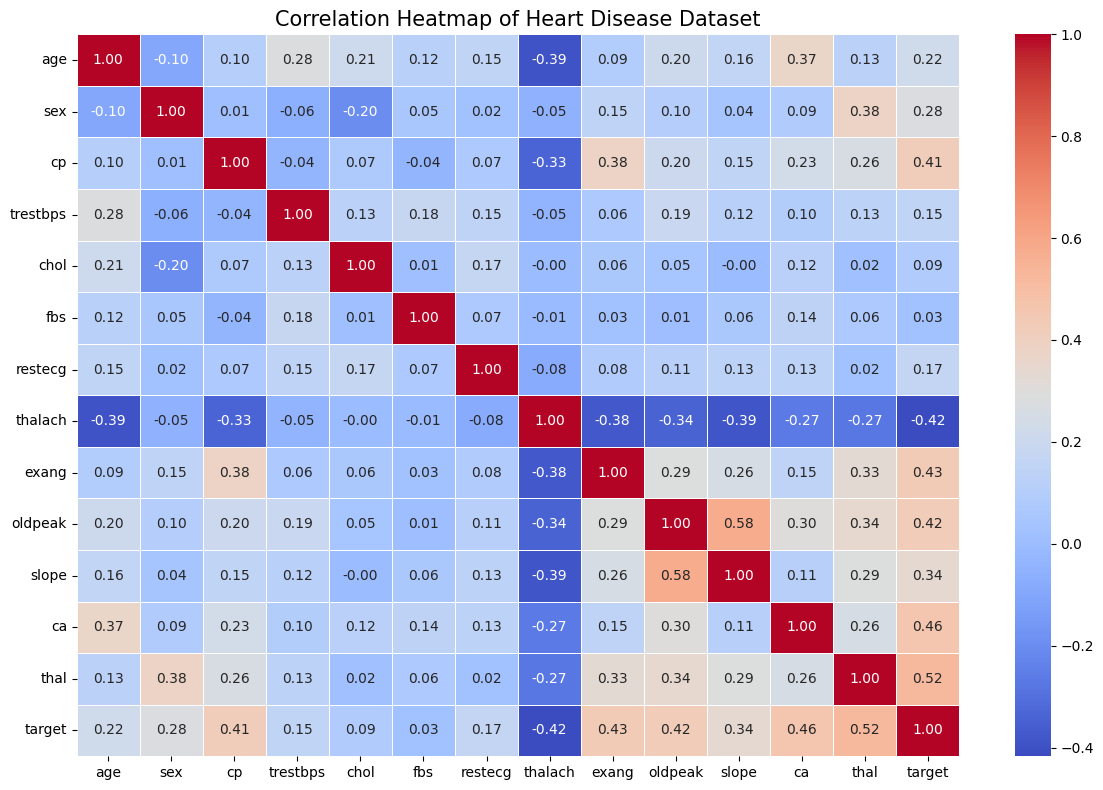

In [16]:
## 4 Correlation Analysis

plt.figure(figsize=(12, 8))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Heart Disease Dataset', fontsize=15)

plt.tight_layout()
plt.show()

In [18]:
target_correlation = (
    df.corr(numeric_only=True)['target']
    .drop('target')
    .sort_values(ascending=False)
)

print("Feature Correlation with Target:\n")
print(target_correlation)

Feature Correlation with Target:

thal        0.522057
ca          0.460033
exang       0.431894
oldpeak     0.424510
cp          0.414446
slope       0.339213
sex         0.276816
age         0.223120
restecg     0.169202
trestbps    0.150825
chol        0.085164
fbs         0.025264
thalach    -0.417167
Name: target, dtype: float64


## Feature Selection

In [19]:
X = df.drop('target', axis=1)
y = df['target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (303, 13)
Target shape: (303,)


## Train-Test Split

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (242, 13)
Testing features: (61, 13)
Training target: (242,)
Testing target: (61,)


## lets train model = Logistic Regression

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [22]:
categorical_features = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

numerical_features = [
    'age', 'trestbps', 'chol',
    'thalach', 'oldpeak'
]

In [23]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

In [25]:
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [26]:
y_pred_lr = lr_model.predict(X_test)

print("Actual values:")
print(y_test.head().tolist())

print("\nPredicted values:")
print(y_pred_lr[:5])

Actual values:
[0, 0, 0, 0, 0]

Predicted values:
[0 1 0 0 0]


In [27]:
## Evaluate the Model
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("ROC-AUC:", round(roc_auc_score(
    y_test,
    lr_model.predict_proba(X_test)[:, 1]
), 4))

Accuracy: 0.8852

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Confusion Matrix:
[[28  5]
 [ 2 26]]
ROC-AUC: 0.9665


## Now we'll train our second machine learning model: Random Forest

In [28]:
from sklearn.ensemble import RandomForestClassifier

In [30]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [31]:
y_pred_rf = rf_model.predict(X_test)

print("Actual values:")
print(y_test.head().tolist())

print("\nPredicted values:")
print(y_pred_rf[:5])

Actual values:
[0, 0, 0, 0, 0]

Predicted values:
[0 1 0 0 0]


In [32]:
## evaluate the model 
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nROC-AUC:", round(
    roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]),
    4
))

Accuracy: 0.8852

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61


Confusion Matrix:
[[28  5]
 [ 2 26]]

ROC-AUC: 0.9443


In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [35]:
## Initial Mfrom sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9665
Random Forest,0.8852,0.8387,0.9286,0.8814,0.9443


## we'll train our third machine learning model: XGBoost

In [36]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [37]:
from xgboost import XGBClassifier

In [38]:
xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        random_state=42,
        eval_metric='logloss'
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [39]:
y_pred_xgb = xgb_model.predict(X_test)

print("Actual values:")
print(y_test.head().tolist())

print("\nPredicted values:")
print(y_pred_xgb[:5])

Actual values:
[0, 0, 0, 0, 0]

Predicted values:
[0 1 0 0 0]


In [40]:
## : Evaluate XGBoost
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_xgb), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_xgb, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nROC-AUC:", round(
    roc_auc_score(
        y_test,
        xgb_model.predict_proba(X_test)[:, 1]
    ), 4
))

Accuracy: 0.8852

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.88      0.89        33
           1       0.86      0.89      0.88        28

    accuracy                           0.89        61
   macro avg       0.88      0.89      0.88        61
weighted avg       0.89      0.89      0.89        61


Confusion Matrix:
[[29  4]
 [ 3 25]]

ROC-AUC: 0.9491


#### Compare All Three Models

In [41]:
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

results_df.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9665
Random Forest,0.8852,0.8387,0.9286,0.8814,0.9443
XGBoost,0.8852,0.8621,0.8929,0.8772,0.9491


## let's visualize the performance of all three models

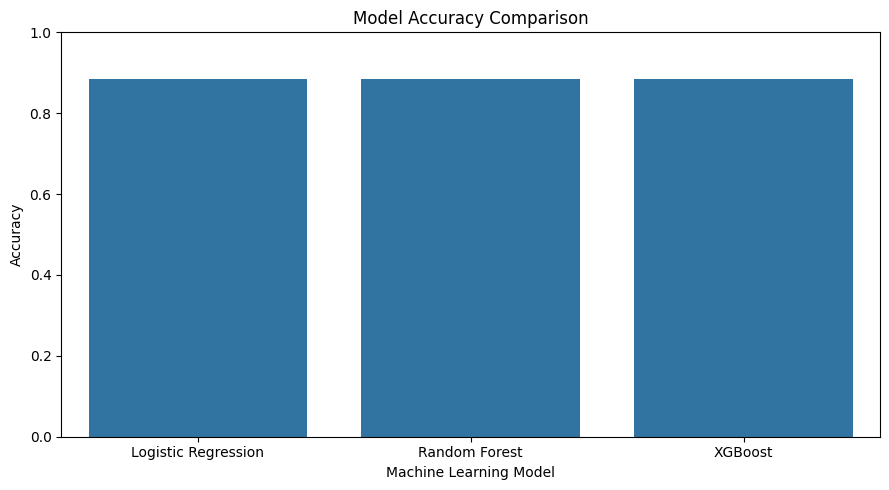

In [42]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df.reset_index(),
    x='Model',
    y='Accuracy'
)

plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.xlabel('Machine Learning Model')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

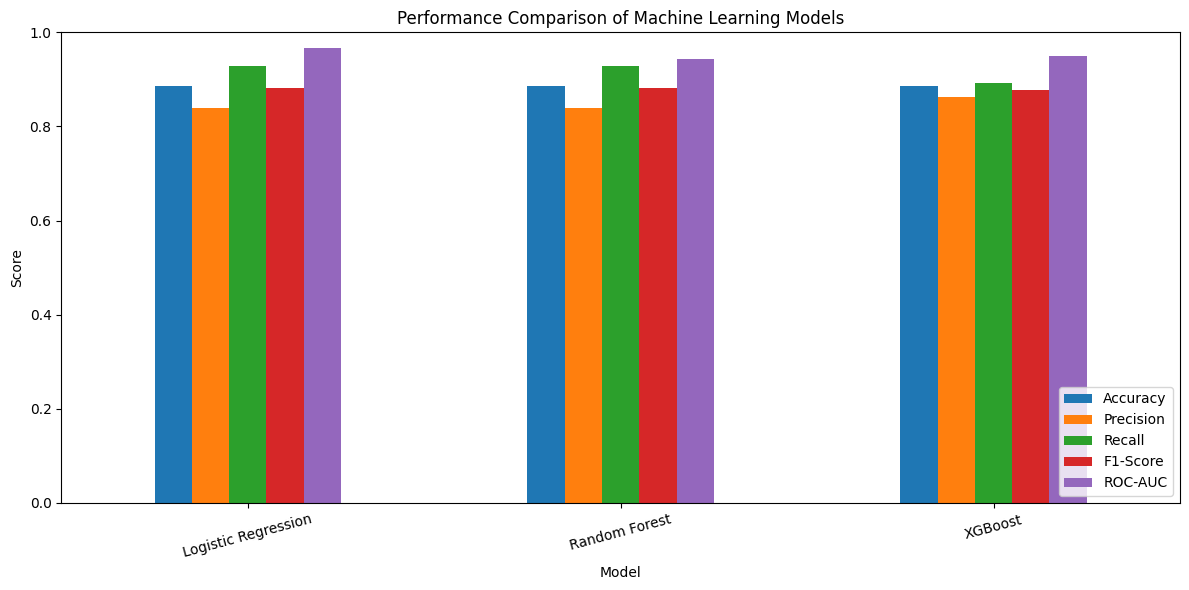

In [43]:
metrics_df = results_df[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
]

metrics_df.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of Machine Learning Models')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Feature Analysis

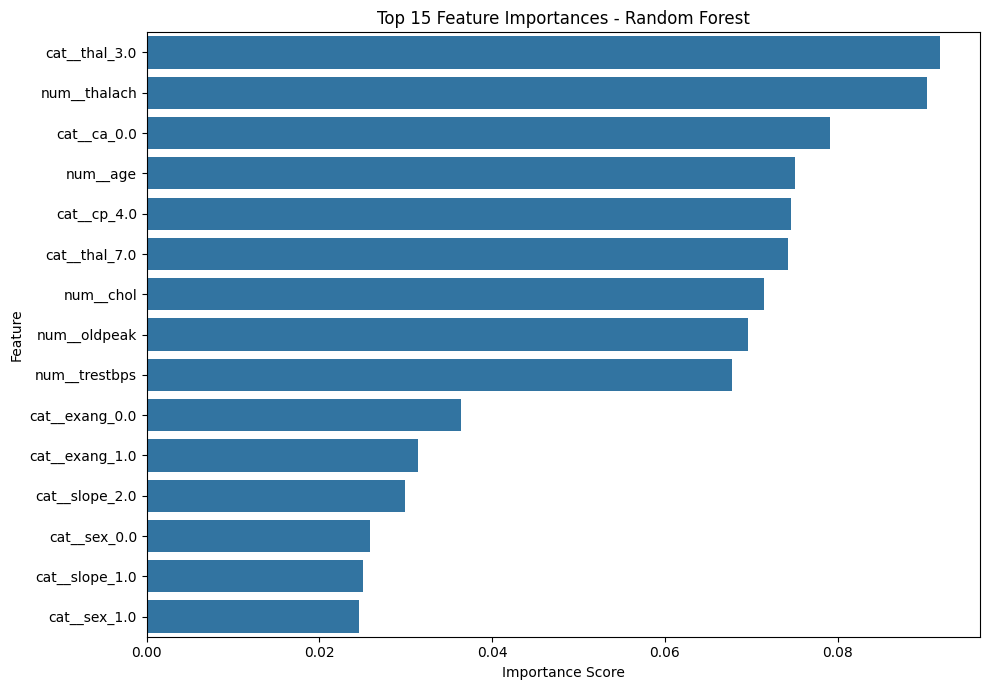

In [44]:
fitted_preprocessor = rf_model.named_steps['preprocessor']

feature_names = fitted_preprocessor.get_feature_names_out()

importances = rf_model.named_steps['classifier'].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Feature Importances - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

#### we'll save our trained model so we can use it later in a Streamlit web application without training it every time.

In [52]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [61]:
import joblib

best_model_name = results_df['ROC-AUC'].idxmax()

model_mapping = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

best_model = model_mapping[best_model_name]

joblib.dump(best_model, 'heart_disease_model.pkl')

print("Model saved successfully!")
print("Selected model:", best_model_name)

Model saved successfully!
Selected model: Logistic Regression


In [62]:
import os

print("Current directory:", os.getcwd())
print("Model file exists:", os.path.exists('heart_disease_model.pkl'))

Current directory: c:\Users\TANAJI\OneDrive\Desktop\GEN AI\Heart Disease Prediction
Model file exists: True


In [63]:
loaded_model = joblib.load('heart_disease_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


## Model Validation Using Cross-Validation

In [64]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [65]:
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    })

cv_results_df = pd.DataFrame(cv_results).set_index("Model")

cv_results_df.round(4)

,Mean Accuracy,Accuracy Std,Mean ROC-AUC,ROC-AUC Std
Model,,,,
Logistic Regression,0.8471,0.0100,0.9025,0.0144
Random Forest,0.8056,0.0345,0.8944,0.0318
XGBoost,0.8223,0.0214,0.8686,0.0226


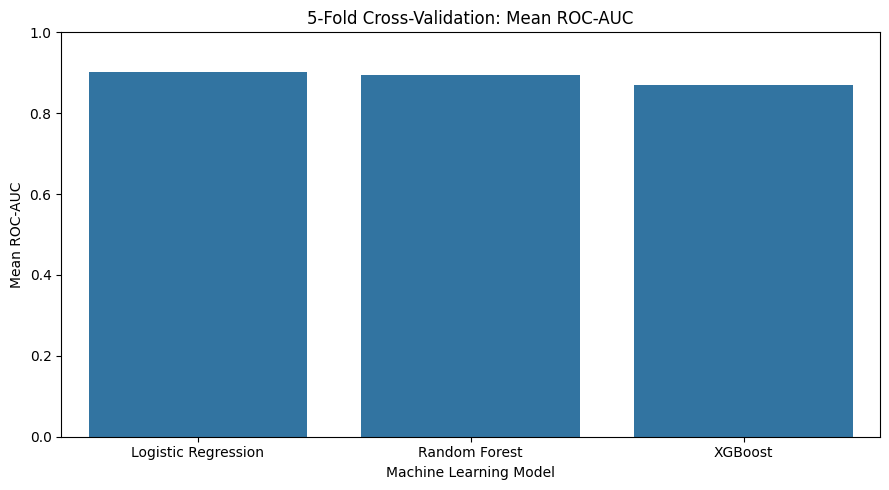

In [66]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cv_results_df.reset_index(),
    x="Model",
    y="Mean ROC-AUC"
)

plt.title("5-Fold Cross-Validation: Mean ROC-AUC")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean ROC-AUC")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [67]:
results_df.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9665
Random Forest,0.8852,0.8387,0.9286,0.8814,0.9443
XGBoost,0.8852,0.8621,0.8929,0.8772,0.9491


In [68]:
best_model_name = cv_results_df['Mean ROC-AUC'].idxmax()

print("Best Preliminary Model:", best_model_name)

print(
    "Mean Cross-Validation ROC-AUC:",
    round(cv_results_df.loc[best_model_name, 'Mean ROC-AUC'], 4)
)

Best Preliminary Model: Logistic Regression
Mean Cross-Validation ROC-AUC: 0.9025


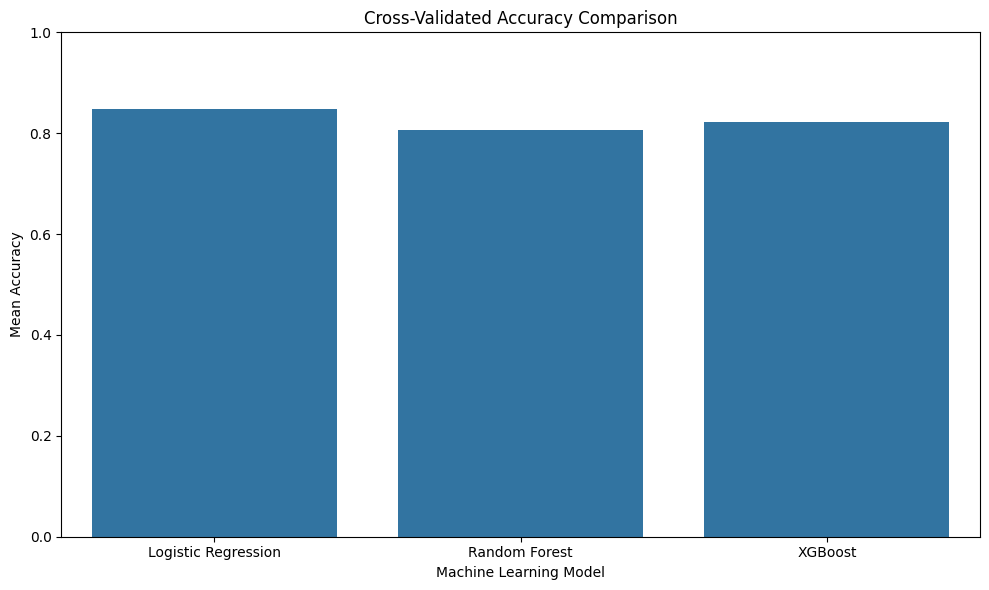

In [69]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cv_results_df.reset_index(),
    x='Model',
    y='Mean Accuracy'
)

plt.title('Cross-Validated Accuracy Comparison')
plt.xlabel('Machine Learning Model')
plt.ylabel('Mean Accuracy')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [70]:
import joblib

model_mapping = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

best_model = model_mapping[best_model_name]

joblib.dump(best_model, 'heart_disease_model.pkl')

print(f"Saved model: {best_model_name}")

Saved model: Logistic Regression
